# Day 9 — Missing Values & Duplicates Deep Dive

**Author:** [Your Name]  
**Date:** 2025-11-15  
**Topic:** Missing data patterns, imputation, fuzzy deduplication

**Objectives:**
1. Analyze missing data patterns (MCAR, MAR, MNAR)
2. Visualize missing data
3. Apply imputation strategies
4. Detect exact, partial, and fuzzy duplicates
5. Build a missing value report

**Data:** Day 4 + Day 8 cleaned (customers_v2, installations_v2, commissioning_v2)

In [1]:
# Cell 2 - Imports
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from difflib import SequenceMatcher

# Display settings
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)

print("✅ Imports successful")
print(f"Pandas version: {pd.__version__}")

✅ Imports successful
Pandas version: 2.2.2


In [2]:
# Cell 3 - Load Data
CLEANED_DIR = "../data/cleaned"

# Load Day 8 cleaned data (v2 files)
customers = pd.read_csv(os.path.join(CLEANED_DIR, "customers_v2.csv"))
installations = pd.read_csv(os.path.join(CLEANED_DIR, "installations_v2.csv"))
commissioning = pd.read_csv(os.path.join(CLEANED_DIR, "commissioning_v2.csv"))

print(f"✅ Customers:     {len(customers):,} rows × {len(customers.columns)} cols")
print(f"✅ Installations: {len(installations):,} rows × {len(installations.columns)} cols")
print(f"✅ Commissioning: {len(commissioning):,} rows × {len(commissioning.columns)} cols")

✅ Customers:     5,200 rows × 9 cols
✅ Installations: 4,451 rows × 8 cols
✅ Commissioning: 3,110 rows × 5 cols


In [3]:
# Cell 4 - Missing Value Table
def missing_table(df, name):
    table = pd.DataFrame({
        "Missing": df.isnull().sum(),
        "Percent": (df.isnull().sum() / len(df) * 100).round(2),
        "Dtype": df.dtypes.astype(str),
    }).sort_values("Missing", ascending=False)
    table = table[table["Missing"] > 0]
    print(f"\n=== {name} ===")
    if len(table) == 0:
        print("   ✅ No missing values")
    else:
        print(table.to_string())
    return table

missing_cust = missing_table(customers, "CUSTOMERS")
missing_inst = missing_table(installations, "INSTALLATIONS")
missing_comm = missing_table(commissioning, "COMMISSIONING")


=== CUSTOMERS ===
                Missing  Percent    Dtype
Contact_Number      164     3.15  float64

=== INSTALLATIONS ===
                   Missing  Percent    Dtype
Solar_Capacity_KW      151     3.39  float64
Installation_Date       81     1.82   object

=== COMMISSIONING ===
                    Missing  Percent   Dtype
Commissioning_Date      554    17.81  object
System_Test_Result      469    15.08  object


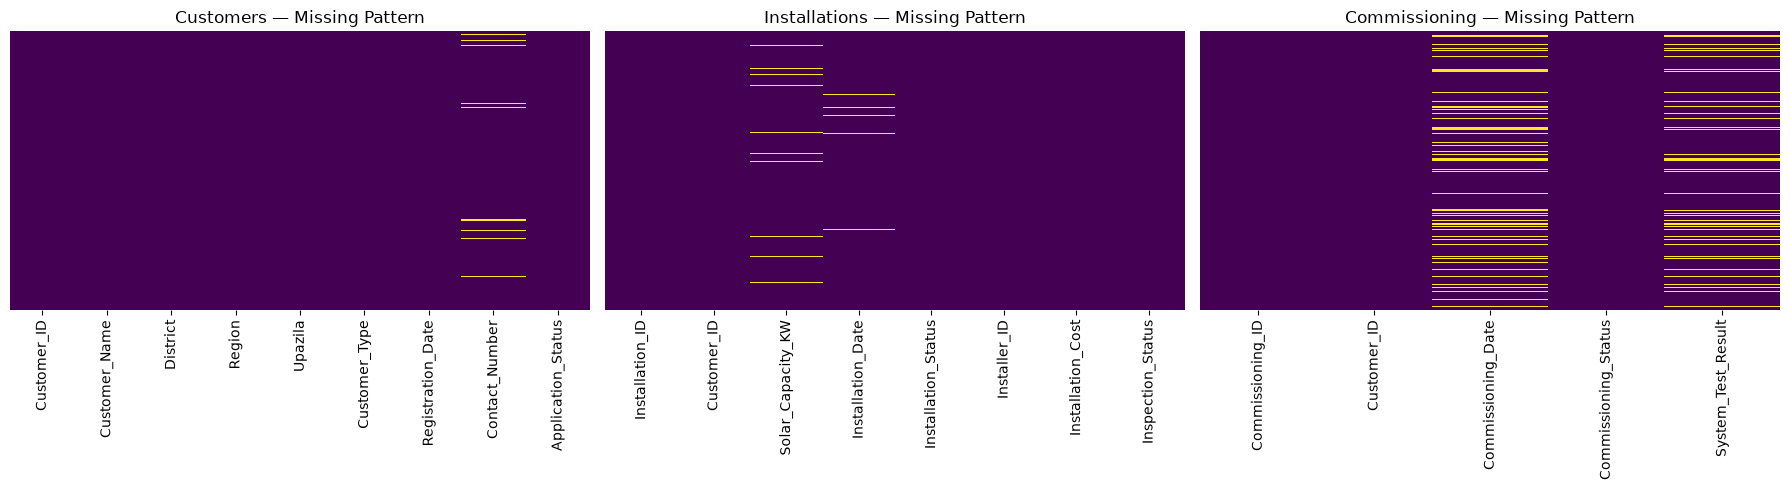

In [4]:
# Cell 5 - Missing Pattern Heatmap
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, df, name in zip(
    axes,
    [customers, installations, commissioning],
    ["Customers", "Installations", "Commissioning"]
):
    sns.heatmap(df.isnull(), cbar=False, yticklabels=False, ax=ax, cmap="viridis")
    ax.set_title(f"{name} — Missing Pattern")

plt.tight_layout()
plt.show()

In [5]:
# Cell 6 - Is Contact Missing Random? (MCAR test)
cust = customers.copy()
cust["has_contact"] = cust["Contact_Number"].notna() & (cust["Contact_Number"] != "MISSING")

print("=== Contact Missing Rate by Customer_Type ===")
print(cust.groupby("Customer_Type")["has_contact"].mean().round(3))

print("\n=== Contact Missing Rate by Region ===")
print(cust.groupby("Region")["has_contact"].mean().round(3))

=== Contact Missing Rate by Customer_Type ===
Customer_Type
Commercial       0.969
Industrial       0.966
Institutional    0.973
Residential      0.966
Name: has_contact, dtype: float64

=== Contact Missing Rate by Region ===
Region
Central    0.965
East       0.967
North      0.968
South      0.977
West       0.964
Name: has_contact, dtype: float64


In [6]:
# Cell 7 - Contact Imputation
customers_v2 = customers.copy()
customers_v2["Contact_Missing"] = (customers_v2["Contact_Number"] == "MISSING")

print(f"Missing contacts: {customers_v2['Contact_Missing'].sum()}")
print(f"Contact missing %: {customers_v2['Contact_Missing'].mean() * 100:.2f}%")
print("\n✅ Contact marked, not filled (data entry gap — legitimate)")

Missing contacts: 0
Contact missing %: 0.00%

✅ Contact marked, not filled (data entry gap — legitimate)


In [7]:
# Cell 8 - Commissioning Missing by Status
comm = commissioning.copy()

print("=== Missing Commissioning Date by Status ===")
for status in ["Completed", "Pending", "Failed"]:
    group = comm[comm["Commissioning_Status"] == status]
    if len(group) > 0:
        missing_pct = group["Commissioning_Date"].isnull().mean() * 100
        print(f"  {status:12s}: {len(group):>5} records | {missing_pct:>5.1f}% missing")

=== Missing Commissioning Date by Status ===
  Completed   :  2641 records |   3.2% missing
  Pending     :   300 records | 100.0% missing
  Failed      :   169 records | 100.0% missing


In [8]:
# Cell 9 - Duplicate Analysis
print("=== DUPLICATE ANALYSIS ===")

print("\nCustomers:")
print(f"  Exact row duplicates:        {customers.duplicated().sum()}")
print(f"  Customer_ID duplicates:      {customers['Customer_ID'].duplicated().sum()}")
print(f"  Name + District duplicates:  {customers.duplicated(subset=['Customer_Name', 'District']).sum()}")

print("\nInstallations:")
print(f"  Installation_ID duplicates:  {installations['Installation_ID'].duplicated().sum()}")
print(f"  Customer_ID duplicates:      {installations['Customer_ID'].duplicated().sum()}")

print("\nCommissioning:")
print(f"  Commissioning_ID duplicates: {commissioning['Commissioning_ID'].duplicated().sum()}")
print(f"  Customer_ID duplicates:      {commissioning['Customer_ID'].duplicated().sum()}")

=== DUPLICATE ANALYSIS ===

Customers:
  Exact row duplicates:        0
  Customer_ID duplicates:      0
  Name + District duplicates:  2453

Installations:
  Installation_ID duplicates:  0
  Customer_ID duplicates:      23

Commissioning:
  Commissioning_ID duplicates: 0
  Customer_ID duplicates:      12


In [9]:
# Cell 10 - Fuzzy Name Matching
def similarity(a, b):
    return SequenceMatcher(None, str(a).lower().strip(), str(b).lower().strip()).ratio()

duplicates_found = []

# Use blocking by District for performance
for district, group in customers.groupby("District"):
    if len(group) < 2:
        continue
    names = group["Customer_Name"].tolist()
    ids = group["Customer_ID"].tolist()
    
    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            sim = similarity(names[i], names[j])
            if sim >= 0.85:
                duplicates_found.append({
                    "District": district,
                    "ID_1": ids[i],
                    "Name_1": names[i],
                    "ID_2": ids[j],
                    "Name_2": names[j],
                    "Similarity": round(sim, 3),
                })

fuzzy_dups = pd.DataFrame(duplicates_found)
print(f"=== FUZZY NAME DUPLICATES ===")
print(f"Found: {len(fuzzy_dups)} pairs with similarity >= 0.85")

if len(fuzzy_dups) > 0:
    print(fuzzy_dups.sort_values("Similarity", ascending=False).head(20).to_string())

=== FUZZY NAME DUPLICATES ===
Found: 5388 pairs with similarity >= 0.85
      District        ID_1            Name_1        ID_2            Name_2  Similarity
5387   Tangail  CUST-04853       Karim Begum  CUST-04948       Karim Begum         1.0
0     Barishal  CUST-00018     Nusrat Rahman  CUST-02291     Nusrat Rahman         1.0
1     Barishal  CUST-00041      Nusrat Akter  CUST-02151      Nusrat Akter         1.0
5386   Tangail  CUST-04660     Murshida Alam  CUST-04780     Murshida Alam         1.0
3     Barishal  CUST-00058  Murshida Hossain  CUST-02480  Murshida Hossain         1.0
4     Barishal  CUST-00064        Anwar Alam  CUST-01883        Anwar Alam         1.0
5     Barishal  CUST-00064        Anwar Alam  CUST-02922        Anwar Alam         1.0
5385   Tangail  CUST-04659      Shilpi Begum  CUST-04925      Shilpi Begum         1.0
7     Barishal  CUST-00074      Shilpi Uddin  CUST-01526      Shilpi Uddin         1.0
8     Barishal  CUST-00074      Shilpi Uddin  CUST-03163  

In [10]:
# Cell 11 - Save Missing Report
REPORTS_DIR = "../reports"
os.makedirs(REPORTS_DIR, exist_ok=True)
output_file = os.path.join(REPORTS_DIR, "Day9_Missing_Report.xlsx")

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    if len(missing_cust) > 0:
        missing_cust.to_excel(writer, sheet_name="Customers_Missing")
    if len(missing_inst) > 0:
        missing_inst.to_excel(writer, sheet_name="Installations_Missing")
    if len(missing_comm) > 0:
        missing_comm.to_excel(writer, sheet_name="Commissioning_Missing")
    
    status_report = comm.groupby("Commissioning_Status").agg(
        Total=("Commissioning_ID", "count"),
        Missing_Date=("Commissioning_Date", lambda x: x.isnull().sum()),
    ).reset_index()
    status_report["Missing_%"] = (
        status_report["Missing_Date"] / status_report["Total"] * 100
    ).round(2)
    status_report.to_excel(writer, sheet_name="Comm_Status_Missing", index=False)
    
    if len(fuzzy_dups) > 0:
        fuzzy_dups.to_excel(writer, sheet_name="Fuzzy_Duplicates", index=False)

print(f"✅ Saved: {output_file}")

✅ Saved: ../reports\Day9_Missing_Report.xlsx
